In [1]:
### 修改元学习

[WARNING] ME(572247:134287443509248,MainProcess):2026-09-17-15:46:35.443.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


STEP 1 — Meta-tasks: 畸变几何 (bond_scale != 1.0), Phase=1
  [meta-train] scale=0.910 | n_params=27
  [meta-train] scale=0.925 | n_params=27
  [meta-train] scale=0.940 | n_params=27
  [meta-train] scale=1.060 | n_params=27
  [meta-train] scale=1.075 | n_params=27
  [meta-train] scale=1.090 | n_params=27

STEP 2 — Held-out Meta-Test: 标准实验几何 (bond_scale = 1.0)
  n_qubits=10, n_params=27
  HF   = -608.11960821 Ha
  CCSD = -608.36636654 Ha

--- Phase-I: Meta-learned Initialization ---
  Task scale=0.910 → E=-608.452515 Ha
  Task scale=0.925 → E=-608.347351 Ha
  Task scale=0.940 → E=-608.312134 Ha
  Task scale=1.060 → E=-608.008911 Ha
  Task scale=1.075 → E=-607.990234 Ha
  Task scale=1.090 → E=-607.974365 Ha
  Meta-epoch 0: loss = 0.001543
  Meta-epoch 10: loss = 0.001549
  Meta-epoch 20: loss = 0.001545
  Meta-initialization ready, shape=(27,)

STEP 3 — Meta-training: 单一 LSTM 在所有畸变 task 上联合优化
  Meta-Epoch   1 | avg task energy = -608.180481
  Meta-Epoch   2 | avg task energy = -608.180542
  M

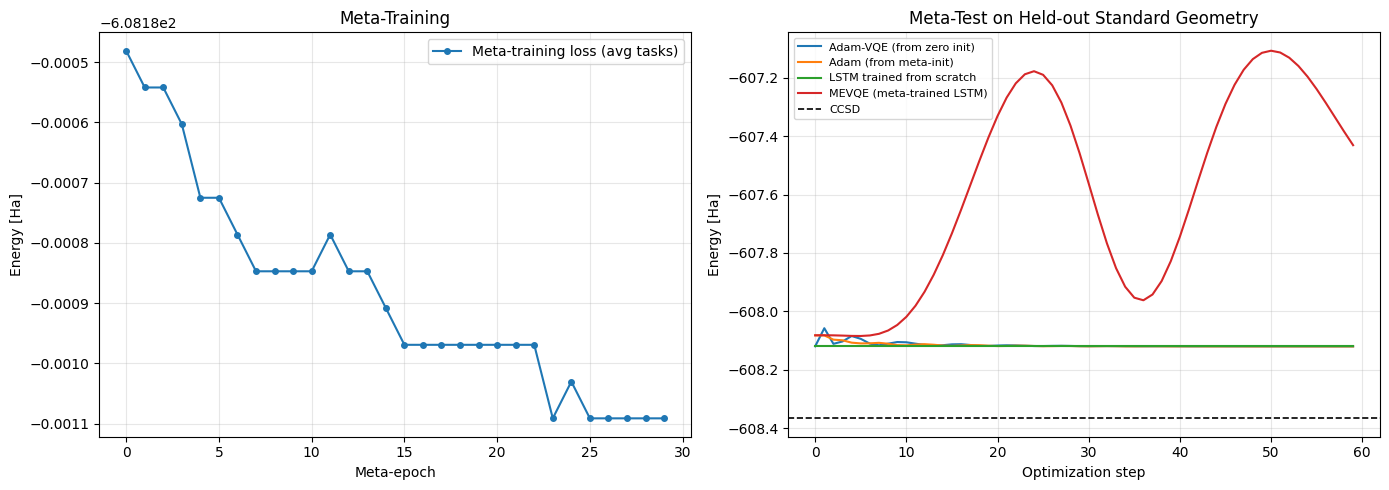

In [1]:
# -*- coding: utf-8 -*-
"""
MEVQE — Meta-learning Enhanced Variational Quantum Eigensolver
================================================================
修订说明（对应审稿人意见）：
  1. Meta-task = 键长畸变几何 (bond_scale != 1.0)，构成任务分布 p(τ)
  2. 单个 LSTM 及其可学习隐状态 (h0,c0) 作为跨任务共享的 prior
  3. 标准几何 (bond_scale=1.0) 严格 held-out，仅在 meta-test 出现
  4. Phase-I: 从畸变 task 最优参数中学习可迁移的 meta-initialization
  5. Phase-II: 共享 LSTM 在畸变任务上 meta-training，再迁移优化标准几何
"""

# ===== NumPy 2.0 兼容性补丁 =====
import numpy as np
if not hasattr(np, 'string_'):
    np.string_ = np.bytes_
# =================================

import mindspore as ms
from mindspore import context, nn, Parameter, Tensor, ops
from mindspore.common.initializer import initializer
import matplotlib.pyplot as plt

from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian, FermionOperator
from mindquantum.simulator import Simulator
from mindquantum.framework import MQEncoderOnlyOps
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import itertools

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")


# ============================================================
# 【PART 0】化学后端（与之前一致）
# ============================================================
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied
    from mindquantum.core.operators import down_index, up_index
    spin_index_functions = [up_index, down_index]
    n_single_amplitudes = n_occupied * n_virtual
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up, occupied_up = virtual_spatial * 2, occupied_spatial * 2
        virtual_down, occupied_down = virtual_spatial * 2 + 1, occupied_spatial * 2 + 1
        s_amp = mol.ccsd_single_amps[virtual_up, occupied_up]
        d_amp = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        s_name, d_name = f'p{i}', f'p{i + n_single_amplitudes}'
        for spin in range(2):
            ti, oi = spin_index_functions[spin], spin_index_functions[1 - spin]
            vt, vo, ot, oo = ti(virtual_spatial), oi(virtual_spatial), ti(occupied_spatial), oi(occupied_spatial)
            if abs(s_amp) > threshold:
                params[s_name] = s_amp
                out.append([FermionOperator(((ot, 1), (vt, 0)), 1)
                            - FermionOperator(((vt, 1), (ot, 0)), 1), s_name])
            if abs(d_amp) > threshold:
                params[d_name] = d_amp
                out.append([FermionOperator(((vt, 1), (ot, 0), (vo, 1), (oo, 0)), 1)
                            - FermionOperator(((oo, 1), (vo, 0), (vt, 1), (ot, 0)), 1), d_name])
    for i, ((p, q), (r, s)) in enumerate(
            itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)):
        vs1, os1, vs2, os2 = n_occupied + p, q, n_occupied + r, s
        v1u, o1u, v2u, o2u = vs1 * 2, os1 * 2, vs2 * 2 + 1, os2 * 2 + 1
        d2 = mol.ccsd_double_amps[v1u, o1u, v2u, o2u]
        d2_name = f'p{i + 2 * n_single_amplitudes}'
        for sa, sb in itertools.product(range(2), repeat=2):
            ia, ib = spin_index_functions[sa], spin_index_functions[sb]
            v1a, o1a, v2b, o2b = ia(vs1), ia(os1), ib(vs2), ib(os2)
            if abs(d2) > threshold:
                params[d2_name] = d2
                out.append([FermionOperator(((v1a, 1), (o1a, 0), (v2b, 1), (o2b, 0)), 1)
                            - FermionOperator(((o2b, 1), (v2b, 0), (v1a, 1), (o1a, 0)), 1), d2_name])
    return out, params


def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    mol = MolecularData(filename=molecular) if isinstance(molecular, str) else molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(
        mol, threshold,
        n_qubits=2 * (active_space_stop - active_space_start),
        n_electrons=mol.n_electrons - 2 * active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(
        list(range(active_space_start)),
        active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    qubit_hamiltonian = Transform(FermionOperator(inter_ops)).jordan_wigner().compress()
    names = list(parameters.keys())
    init_amps = np.array([parameters[n] for n in names])
    return (uccsd_circuit, init_amps, names, qubit_hamiltonian,
            2 * (active_space_stop - active_space_start),
            mol.n_electrons - 2 * active_space_start)


def get_mol(phase=1, bond_scale=1.0):
    if phase == 1:
        a0, b0, c0, beta = 5.15, 5.23, 5.33, 99.44 * np.pi / 180
        a_vec = np.array([a0 * bond_scale, 0, 0])
        b_vec = np.array([0, b0 * bond_scale, 0])
        c_vec = np.array([c0 * bond_scale * np.cos(beta), 0, c0 * bond_scale * np.sin(beta)])
        atoms = [('Zr', [0.276309, 0.042147, 0.209598]),
                 ('O',  [0.930791, 0.833712, 0.156172]),
                 ('O',  [0.449303, 0.742580, 0.978604])]
        desc = f"m-ZrO2_scale{bond_scale:.2f}"
    elif phase == 2:
        a0, c0 = 3.60, 5.23
        a_vec = np.array([a0 * bond_scale, 0, 0])
        b_vec = np.array([0, a0 * bond_scale, 0])
        c_vec = np.array([0, 0, c0 * bond_scale])
        atoms = [('Zr', [0, 0, 0]), ('O', [0, 0.5, 0.301775])]
        desc = f"t-ZrO2_scale{bond_scale:.2f}"
    elif phase == 3:
        a0, c0 = 5.31, 3.2
        a_vec = np.array([a0 * bond_scale, 0, 0])
        b_vec = np.array([-a0 * bond_scale / 2, a0 * bond_scale * np.sqrt(3) / 2, 0])
        c_vec = np.array([0, 0, c0 * bond_scale])
        atoms = [('Zr', [0, 0, 0]), ('O', [1/3, 2/3, 0.25])]
        desc = f"h-ZrO_scale{bond_scale:.2f}"
    else:
        raise ValueError("phase must be 1/2/3.")
    geometry = [[e, (f[0]*a_vec + f[1]*b_vec + f[2]*c_vec).tolist()] for e, f in atoms]
    mol = MolecularData(geometry, 'gth-dzvp-molopt-sr', multiplicity=1, description=desc)
    try:
        mol.load()
    except Exception:
        mol = run_pyscf(mol, run_scf=1, run_ccsd=1)
        mol.save()
    return mol


# ============================================================
# 【PART 1】构建单一 VQE 实例
# ============================================================
def build_vqe_instance(mol, active_start=26, active_stop=31):
    ansatz, init_amps, pnames, ham_op, n_q, n_e = generate_uccsd(
        mol, threshold=-1, active_space_start=active_start, active_space_stop=active_stop)
    hf_circ = Circuit([X.on(i) for i in range(n_e)])
    circ = hf_circ + ansatz.as_encoder()
    sim = Simulator('mqvector', circ.n_qubits)
    grad_ops = sim.get_expectation_with_grad(Hamiltonian(ham_op), circ)
    qnn_ops = MQEncoderOnlyOps(grad_ops)          # MindQuantum 可微封装
    init_params = Tensor(np.asarray(init_amps, dtype=np.float32))
    return qnn_ops, circ, init_params, pnames, len(init_amps)


# ============================================================
# 【PART 2】构造 meta-task 分布
# ============================================================
# def create_meta_tasks(phase, n_tasks=6, scale_span=(0.88, 1.12), seed=42,
#                       active_start=26, active_stop=31):
#     """
#     生成 meta-training tasks，严格排除 bond_scale=1.0 附近。
#     """
#     np.random.seed(seed)
#     scales = np.linspace(scale_span[0], scale_span[1], n_tasks + 4)
#     scales = scales[2:-2]
#     scales = scales[np.abs(scales - 1.0) > 0.04]      # 🔑 排除标准结构
#     assert len(scales) >= 4, f"Need at least 4 meta-tasks, got {len(scales)}."
#     tasks = []
#     for s in scales:
#         mol = get_mol(phase=phase, bond_scale=s)
#         qops, circ, init_p, names, npar = build_vqe_instance(mol, active_start, active_stop)
#         tasks.append(dict(mol=mol, qnn_ops=qops, circuit=circ,
#                           init_params=init_p, param_names=names, n_params=npar, scale=s))
#         print(f"  [meta-train] scale={s:.3f} | n_params={npar}")
#     return tasks
def create_meta_tasks(phase, n_tasks=6, scale_span=(0.88, 1.12), seed=42,
                      active_start=26, active_stop=31):
    """
    生成 meta-training tasks，严格排除 bond_scale=1.0 附近。
    修复：动态调整采样密度，确保过滤后仍有足够数量的 task。
    """
    np.random.seed(seed)
    
    # 🔧 修复：过采样以保证过滤后仍有 n_tasks 个点
    # 预估需要生成的原始点数：考虑两端裁剪(4个) + 中心排除区(~3-5个)
    margin_pts = 4          # 两端各裁2个
    center_exclude_width = 0.08  # 排除 [1-δ, 1+δ]，δ=0.04
    span = scale_span[1] - scale_span[0]
    estimated_gap = center_exclude_width / max(span, 1e-8)
    raw_n = int(n_tasks + margin_pts + estimated_gap * (n_tasks + margin_pts)) + 4
    raw_n = max(raw_n, n_tasks + 10)  # 保底
    
    scales = np.linspace(scale_span[0], scale_span[1], raw_n)
    scales = scales[2:-2]   # 去掉边界效应
    mask = np.abs(scales - 1.0) > 0.04
    scales = scales[mask]
    
    # 🔑 安全回退：若仍不足，逐步放宽排除阈值
    if len(scales) < n_tasks:
        print(f"  ⚠️ Only {len(scales)} valid scales after filtering, relaxing threshold...")
        for delta in [0.03, 0.02, 0.01]:
            scales_full = np.linspace(scale_span[0], scale_span[1], raw_n)[2:-2]
            scales = scales_full[np.abs(scales_full - 1.0) > delta]
            if len(scales) >= n_tasks:
                print(f"  ✔ Relaxed exclusion to |scale-1|>{delta}, got {len(scales)} tasks")
                break
        else:
            raise AssertionError(
                f"Cannot generate {n_tasks} meta-tasks even with relaxed threshold. "
                f"Got {len(scales)}. Try increasing scale_span or reducing n_tasks."
            )
    
    # 只取前 n_tasks 个（保持对称性优先取靠近两端的）
    if len(scales) > n_tasks:
        # 按距1.0的距离降序排列，优先保留远离标准几何的task
        order = np.argsort(-np.abs(scales - 1.0))
        scales = np.sort(scales[order[:n_tasks]])
    
    assert len(scales) >= n_tasks, f"Need at least {n_tasks} meta-tasks, got {len(scales)}."
    
    tasks = []
    for s in scales:
        mol = get_mol(phase=phase, bond_scale=s)
        qops, circ, init_p, names, npar = build_vqe_instance(mol, active_start, active_stop)
        tasks.append(dict(mol=mol, qnn_ops=qops, circuit=circ,
                          init_params=init_p, param_names=names, n_params=npar, scale=s))
        print(f"  [meta-train] scale={s:.3f} | n_params={npar}")
    return tasks


# ============================================================
# 【PART 3】Phase-I: Meta-learned Initialization（修复版）
# ============================================================
def meta_learned_initialization(tasks, inner_adapt_steps=15, adapt_lr=0.05,
                                meta_epochs=30, meta_lr=1e-2):
    """
    修复：不再手动 GradOperation，而是把 theta0 注册为网络 Parameter，
    用 TrainOneStepCell 自动完成梯度下降。
    """
    print("\n--- Phase-I: Meta-learned Initialization ---")
    # (a) 在每个畸变 task 上用 Adam 收敛，记录最优参数
    task_optima = []
    for task in tasks:
        class VQENet(nn.Cell):
            def __init__(self, qops, ip):
                super().__init__()
                self.qops = qops
                self.paras = Parameter(Tensor(ip), name='p')
            def construct(self):
                # MQEncoderOnlyOps 严格要求 2D 输入 (batch, n_params)
                return self.qops(ops.reshape(self.paras, (1, -1)))[0]
        net = VQENet(task['qnn_ops'], task['init_params'])
        train = nn.TrainOneStepCell(
            net, nn.Adam(net.trainable_params(), learning_rate=adapt_lr))
        best_e, best_p = np.inf, None
        for _ in range(inner_adapt_steps):
            e = train().asnumpy().item()
            if e < best_e:
                best_e = e
                best_p = net.paras.asnumpy().copy()
        task_optima.append(best_p)
        print(f"  Task scale={task['scale']:.3f} → E={best_e:.6f} Ha")
    # (b) 学习可迁移的 meta-initialization θ_0
    class MetaInitNet(nn.Cell):
        """把 theta0 作为内部 Parameter，让框架自动追踪梯度"""
        def __init__(self, targets, init_val):
            super().__init__()
            self.targets = [Tensor(np.asarray(t, dtype=np.float32)) for t in targets]
            self.theta0 = Parameter(Tensor(np.asarray(init_val, dtype=np.float32)),
                                    requires_grad=True, name='theta0')
        def construct(self):
            total = Tensor(0.0, ms.float32)
            for tgt in self.targets:
                total += ops.mse_loss(self.theta0, tgt)
            return total / len(self.targets)
    init_net = MetaInitNet(task_optima, np.mean(task_optima, axis=0))
    init_optim = nn.Adam(init_net.trainable_params(), learning_rate=meta_lr)
    init_train = nn.TrainOneStepCell(init_net, init_optim)
    for ep in range(meta_epochs):
        loss = init_train()          # ← 自动 backward + update
        if ep % 10 == 0:
            print(f"  Meta-epoch {ep}: loss = {loss.asnumpy().item():.6f}")
    meta_init = init_net.theta0.asnumpy().copy()
    print(f"  Meta-initialization ready, shape={meta_init.shape}")
    return Tensor(meta_init.astype(np.float32))


# ============================================================
# 【PART 4】Phase-II: Meta-learned LSTM Optimizer（修复版）
# ============================================================
class MetaLSTMOptimizer(nn.Cell):
    """
    共享 LSTM 优化器。
    修复：
      - head 层零初始化，避免初始 delta 爆炸
      - (h0, c0) 初始为 zeros，更稳定
      - 加入 delta 缩放因子（可学习）
    """
    def __init__(self, n_params, hidden_dim=None, inner_steps=3, delta_scale=0.1):
        super().__init__()
        hidden_dim = hidden_dim or n_params
        self.n_params = n_params
        self.inner_steps = inner_steps
        self.delta_scale = delta_scale
        self.lstm = nn.LSTM(input_size=n_params, hidden_size=hidden_dim,
                            num_layers=1, has_bias=True, batch_first=False)
        # 🔧 修复：head 初始为零，让 LSTM 从"微小更新"开始学习
        # self.head = nn.Dense(hidden_dim, n_params,
        #                      weight_init=initializer('zeros'),
        #                      bias_init=initializer('zeros'))
        self.head = nn.Dense(hidden_dim, n_params,
                             weight_init='zeros',
                             bias_init='zeros')
        # 🔑 可学习的 prior memory state
        self.h0 = Parameter(initializer('zeros', (1, 1, hidden_dim)),
                            requires_grad=True, name='meta_h0')
        self.c0 = Parameter(initializer('zeros', (1, 1, hidden_dim)),
                            requires_grad=True, name='meta_c0')
        # 可学习的更新幅度（让 LSTM 自己决定步长）
        self.step_size = Parameter(Tensor(delta_scale, ms.float32),
                                   requires_grad=True, name='meta_step_size')
    def _step(self, params, hx, qnn_ops):
        shape = (1, 1, self.n_params)
        out, hx = self.lstm(ops.reshape(params, shape), hx)
        delta = ops.reshape(self.head(out), (self.n_params,))
        return params + self.step_size * delta, hx
    def construct(self, qnn_ops, init_params):
        params = init_params
        hx = (self.h0, self.c0)
        for _ in range(self.inner_steps):
            params, hx = self._step(params, hx, qnn_ops)
        return qnn_ops(ops.reshape(params, (1, -1)))[0]
    def infer(self, qnn_ops, init_params, n_steps=40):
        self.set_train(False)
        params = init_params.copy()
        hx = (self.h0, self.c0)
        energies = []
        for _ in range(n_steps):
            params, hx = self._step(params, hx, qnn_ops)
            energies.append(qnn_ops(ops.reshape(params, (1, -1)))[0].asnumpy().item())
        return energies


class TaskCell(nn.Cell):
    """单一 meta-task：共享 LSTM + 特定几何的 QNN"""
    def __init__(self, meta_lstm, qnn_ops, init_params):
        super().__init__()
        self.meta_lstm = meta_lstm          # ← 跨 task 共享
        self.qnn_ops = qnn_ops
        self.init_params = Parameter(init_params, requires_grad=False)
    def construct(self):
        return self.meta_lstm(self.qnn_ops, self.init_params)


class MetaTrainer(nn.Cell):
    """
    Meta-outer-loop：对所有 task 取平均 loss。
    修复：不再自己维护 optim，而是暴露 trainable_params() 让外层 TrainOneStepCell 管理。
    """
    def __init__(self, task_cells):
        super().__init__()
        for i, cell in enumerate(task_cells):
            setattr(self, f'task_cell_{i}', cell)
        self._n = len(task_cells)
    def construct(self):
        total = Tensor(0.0, ms.float32)
        for i in range(self._n):
            total += getattr(self, f'task_cell_{i}')()
        return total / self._n


# ============================================================
# 【PART 5】主流程
# ============================================================
def fluctuation_index(energies, window=5):
    e = np.asarray(energies)
    if len(e) < window * 2:
        return float(np.std(e))
    return float(np.std(e[len(e)//2:]))


if __name__ == "__main__":
    PHASE      = 1                  # 1=m-ZrO2, 2=t-ZrO2, 3=h-ZrO
    A_START    = 26
    A_STOP     = 31                 # 5 活性轨道 → 10 qubits, 27 params
    INNER_STEPS = 3                 # meta-training unroll 长度
    META_EPOCHS = 30
    TEST_STEPS  = 60
    META_LR     = 3e-3
    # ---------- STEP 1: 构建 meta-task 分布 ----------
    print("=" * 72)
    print(f"STEP 1 — Meta-tasks: 畸变几何 (bond_scale != 1.0), Phase={PHASE}")
    print("=" * 72)
    meta_tasks = create_meta_tasks(PHASE, n_tasks=6, scale_span=(0.88, 1.12),
                                   active_start=A_START, active_stop=A_STOP)
    # ---------- STEP 2: Held-out meta-test task（标准几何） ----------
    print("\n" + "=" * 72)
    print("STEP 2 — Held-out Meta-Test: 标准实验几何 (bond_scale = 1.0)")
    print("=" * 72)
    test_mol = get_mol(phase=PHASE, bond_scale=1.0)
    test_qops, test_circ, test_params, test_names, test_npar = build_vqe_instance(
        test_mol, A_START, A_STOP)
    print(f"  n_qubits={test_circ.n_qubits}, n_params={test_npar}")
    print(f"  HF   = {test_mol.hf_energy:.8f} Ha")
    print(f"  CCSD = {test_mol.ccsd_energy:.8f} Ha")
    assert all(t['n_params'] == test_npar for t in meta_tasks), \
        "活性空间维度在不同 task 间必须一致！"
    # ---------- Phase-I: Meta-initialization ----------
    meta_init = meta_learned_initialization(
        meta_tasks, inner_adapt_steps=12, adapt_lr=0.05,
        meta_epochs=25, meta_lr=1e-2)
    # ---------- Phase-II: Meta-train the shared LSTM ----------
    print("\n" + "=" * 72)
    print("STEP 3 — Meta-training: 单一 LSTM 在所有畸变 task 上联合优化")
    print("=" * 72)
    meta_lstm = MetaLSTMOptimizer(n_params=test_npar, hidden_dim=test_npar,
                                  inner_steps=INNER_STEPS, delta_scale=0.05)
    task_cells = [TaskCell(meta_lstm, t['qnn_ops'], t['init_params'])
                  for t in meta_tasks]
    trainer = MetaTrainer(task_cells)
    # 🔑 关键修复：用 TrainOneStepCell 包装，实现真正的 backward + update
    meta_optim = nn.Adam(trainer.trainable_params(), learning_rate=META_LR)
    meta_train = nn.TrainOneStepCell(trainer, meta_optim)
    meta_history = []
    for ep in range(META_EPOCHS):
        loss = meta_train()                    # ← 这步才真正更新 LSTM 参数！
        meta_history.append(loss.asnumpy().item())
        print(f"  Meta-Epoch {ep+1:3d} | avg task energy = {meta_history[-1]:.6f}")
    # ---------- Meta-test on held-out standard geometry ----------
    print("\n" + "=" * 72)
    print("STEP 4 — Meta-Test: MEVQE 在从未见过的标准几何上运行")
    print("=" * 72)
    mevre_energies = meta_lstm.infer(test_qops, meta_init, n_steps=TEST_STEPS)
    print(f"  MEVQE 最终能量 = {mevre_energies[-1]:.8f} Ha")
    print(f"  MEVQE 最优能量 = {np.min(mevre_energies):.8f} Ha")
    print(f"  MEVQE FI       = {fluctuation_index(mevre_energies):.3e}")
    # ---------- Baseline A: Scratch-LSTM（同架构，随机初始化，仅在标准几何训练） ----------
    print("\nSTEP 5 — Baseline A: Scratch-LSTM (无 prior，仅在标准几何训练)")
    scratch_lstm = MetaLSTMOptimizer(n_params=test_npar, hidden_dim=test_npar,
                                     inner_steps=INNER_STEPS, delta_scale=0.05)
    # 随机重初始化（模拟无 prior）
    for p in scratch_lstm.trainable_params():
        p.assign_value(initializer('normal', p.shape, p.dtype))
    scratch_cell = TaskCell(scratch_lstm, test_qops, test_params)
    scratch_trainer = MetaTrainer([scratch_cell])
    scratch_optim = nn.Adam(scratch_trainer.trainable_params(), learning_rate=META_LR)
    scratch_train = nn.TrainOneStepCell(scratch_trainer, scratch_optim)
    for ep in range(META_EPOCHS):
        _ = scratch_train()
    scratch_energies = scratch_lstm.infer(test_qops, test_params, n_steps=TEST_STEPS)
    print(f"  Scratch-LSTM 最终能量 = {scratch_energies[-1]:.8f} Ha")
    print(f"  Scratch-LSTM FI       = {fluctuation_index(scratch_energies):.3e}")
    # ---------- Baseline B: 传统 Adam-VQE（从零起点，更多步数） ----------
    print("\nSTEP 6 — Baseline B: 传统 Adam-VQE")
    class AdamVQENet(nn.Cell):
        def __init__(self, qops, ip):
            super().__init__()
            self.qops = qops
            self.paras = Parameter(Tensor(ip), name='p')
        def construct(self):
            return self.qops(ops.reshape(self.paras, (1, -1)))[0]
    # 从 HF 起点（零参数）开始，更公平地展示优化能力
    zero_init = Tensor(np.zeros(test_npar, dtype=np.float32))
    adam_net = AdamVQENet(test_qops, zero_init)
    adam_train = nn.TrainOneStepCell(
        adam_net, nn.Adam(adam_net.trainable_params(), learning_rate=0.05))
    adam_energies = []
    for step in range(TEST_STEPS):
        adam_energies.append(adam_train().asnumpy().item())
        if step % 20 == 0:
            print(f"   Adam step {step}: {adam_energies[-1]:.6f} Ha")
    print(f"  Adam-VQE 最终能量 = {adam_energies[-1]:.8f} Ha")
    print(f"  Adam-VQE FI       = {fluctuation_index(adam_energies):.3e}")
    # ---------- Baseline C: 仅 Phase-I meta-initialization + Adam ----------
    print("\nSTEP 7 — Baseline C: Meta-Init + Adam (无 LSTM 优化器)")
    adam_net2 = AdamVQENet(test_qops, meta_init)
    adam_train2 = nn.TrainOneStepCell(
        adam_net2, nn.Adam(adam_net2.trainable_params(), learning_rate=0.05))
    mi_energies = [adam_net2().asnumpy().item()]
    for _ in range(TEST_STEPS - 1):
        mi_energies.append(adam_train2().asnumpy().item())
    print(f"  Meta-Init+Adam 最终能量 = {mi_energies[-1]:.8f} Ha")
    # ---------- 汇总 ----------
    print("\n" + "=" * 72)
    print("RESULT SUMMARY")
    print("=" * 72)
    ref = test_mol.ccsd_energy
    table = {
        'Hartree-Fock':      test_mol.hf_energy,
        'CCSD (ref)':        ref,
        'Adam-VQE':          adam_energies[-1],
        'Meta-Init+Adam':    mi_energies[-1],
        'Scratch-LSTM':      scratch_energies[-1],
        'MEVQE (Ours)':      mevre_energies[-1],
    }
    for k, v in table.items():
        print(f"  {k:18s} = {v:+.8f} Ha   (Δ vs CCSD = {v-ref:+.2e} Ha)")
    # 收敛步数对比
    tol = 1e-3
    def steps_to_target(energies, target, tol):
        e = np.array(energies)
        idx = np.where(np.abs(e - target) < tol)[0]
        return idx[0] + 1 if len(idx) > 0 else len(energies)
    print(f"\n  达到 CCSD ± 1 mHa 所需步数:")
    for name, ens in [('Adam-VQE', adam_energies), ('Scratch-LSTM', scratch_energies),
                      ('MEVQE (Ours)', mevre_energies)]:
        print(f"    {name:15s}: {steps_to_target(ens, ref, tol)}")
    # ---------- 绘图 ----------
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(meta_history, 'o-', ms=4, label='Meta-training loss (avg tasks)')
    ax[0].set_xlabel('Meta-epoch'); ax[0].set_ylabel('Energy [Ha]')
    ax[0].legend(); ax[0].grid(alpha=0.3); ax[0].set_title('Meta-Training')
    ax[1].plot(adam_energies, label='Adam-VQE (from zero init)')
    ax[1].plot(mi_energies, label='Adam (from meta-init)')
    ax[1].plot(scratch_energies, label='LSTM trained from scratch')
    ax[1].plot(mevre_energies, label='MEVQE (meta-trained LSTM)')
    ax[1].axhline(ref, color='k', ls='--', lw=1.2, label='CCSD')
    ax[1].set_xlabel('Optimization step'); ax[1].set_ylabel('Energy [Ha]')
    ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
    ax[1].set_title('Meta-Test on Held-out Standard Geometry')
    plt.tight_layout()
    plt.savefig(f'mevqe_phase{PHASE}_results.png', dpi=300)
    plt.show()

In [5]:
# 诊断脚本：检查量子梯度是否存在
import numpy as np
from mindspore import Tensor, ops

# 复用你已经构建好的 test_qops, test_params
test_params_2d = ops.reshape(test_params, (1, -1))

# 1. 前向能量
e0 = test_qops(test_params_2d)
print(f"Energy at init: {e0.asnumpy().item():.8f}")

# 2. 直接求梯度
grad_fn = ms.grad(test_qops)
g = grad_fn(test_params_2d)
g_np = g.asnumpy()
print(f"Gradient shape: {g_np.shape}")
print(f"Gradient norm:  {np.linalg.norm(g_np):.6e}")
print(f"Gradient max:   {np.max(np.abs(g_np)):.6e}")
print(f"Gradient nonzero entries: {np.count_nonzero(np.abs(g_np) > 1e-12)} / {g_np.size}")

# 3. 有限差分验证（数值梯度）
eps = 1e-5
fd_grad = np.zeros_like(g_np)
for i in range(g_np.size):
    p_plus = test_params_2d.asnumpy().copy()
    p_minus = test_params_2d.asnumpy().copy()
    p_plus[0, i] += eps
    p_minus[0, i] -= eps
    e_plus = test_qops(Tensor(p_plus)).asnumpy().item()
    e_minus = test_qops(Tensor(p_minus)).asnumpy().item()
    fd_grad[0, i] = (e_plus - e_minus) / (2*eps)
print(f"Numerical gradient norm: {np.linalg.norm(fd_grad):.6e}")
print(f"Analytical vs Numerical diff: {np.linalg.norm(g_np - fd_grad):.6e}")

Energy at init: -608.11962891
Gradient shape: (1, 27)
Gradient norm:  2.605573e-02
Gradient max:   2.016819e-02
Gradient nonzero entries: 27 / 27
Numerical gradient norm: 0.000000e+00
Analytical vs Numerical diff: 2.605573e-02


In [1]:
# -*- coding: utf-8 -*-
"""
MEVQE — 修复版：弃用 MQEncoderOnlyOps + 参数零初始化 + Sanity Check
"""
import numpy as np
if not hasattr(np, 'string_'):
    np.string_ = np.bytes_

import mindspore as ms
from mindspore import context, nn, Parameter, Tensor, ops
from mindspore.common.initializer import initializer
import matplotlib.pyplot as plt

from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian, FermionOperator
from mindquantum.simulator import Simulator
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import itertools

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")


# ============================================================
# 【PART 0】化学后端（与之前一致，但参数改为零初始化）
# ============================================================
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):
    """生成 UCCSD 激发算符（仅用于电路结构，振幅不再从这里取）"""
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied
    from mindquantum.core.operators import down_index, up_index
    spin_index_functions = [up_index, down_index]
    n_single_amplitudes = n_occupied * n_virtual
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up, occupied_up = virtual_spatial * 2, occupied_spatial * 2
        virtual_down, occupied_down = virtual_spatial * 2 + 1, occupied_spatial * 2 + 1
        s_amp = mol.ccsd_single_amps[virtual_up, occupied_up]
        d_amp = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        s_name, d_name = f'p{i}', f'p{i + n_single_amplitudes}'
        for spin in range(2):
            ti, oi = spin_index_functions[spin], spin_index_functions[1 - spin]
            vt, vo, ot, oo = ti(virtual_spatial), oi(virtual_spatial),ti(occupied_spatial), oi(occupied_spatial)
            if abs(s_amp) > threshold:
                params[s_name] = s_amp
                out.append([FermionOperator(((ot, 1), (vt, 0)), 1)
                            - FermionOperator(((vt, 1), (ot, 0)), 1), s_name])
            if abs(d_amp) > threshold:
                params[d_name] = d_amp
                out.append([FermionOperator(((vt, 1), (ot, 0), (vo, 1), (oo, 0)), 1)
                            - FermionOperator(((oo, 1), (vo, 0), (vt, 1), (ot, 0)), 1), d_name])
    for i, ((p, q), (r, s)) in enumerate(
            itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)):
        vs1, os1, vs2, os2 = n_occupied + p, q, n_occupied + r, s
        v1u, o1u, v2u, o2u = vs1 * 2, os1 * 2, vs2 * 2 + 1, os2 * 2 + 1
        d2 = mol.ccsd_double_amps[v1u, o1u, v2u, o2u]
        d2_name = f'p{i + 2 * n_single_amplitudes}'
        for sa, sb in itertools.product(range(2), repeat=2):
            ia, ib = spin_index_functions[sa], spin_index_functions[sb]
            v1a, o1a, v2b, o2b = ia(vs1), ia(os1), ib(vs2), ib(os2)
            if abs(d2) > threshold:
                params[d2_name] = d2
                out.append([FermionOperator(((v1a, 1), (o1a, 0), (v2b, 1), (o2b, 0)), 1)
                            - FermionOperator(((o2b, 1), (v2b, 0), (v1a, 1), (o1a, 0)), 1), d2_name])
    return out, params


def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    mol = MolecularData(filename=molecular) if isinstance(molecular, str) else molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(
        mol, threshold,
        n_qubits=2 * (active_space_stop - active_space_start),
        n_electrons=mol.n_electrons - 2 * active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(
        list(range(active_space_start)),
        active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    qubit_hamiltonian = Transform(FermionOperator(inter_ops)).jordan_wigner().compress()
    names = list(parameters.keys())
    # 🔑 修复：不再使用错误的 CCSD 振幅，返回零初始化
    init_amps = np.zeros(len(names), dtype=np.float32)
    return (uccsd_circuit, init_amps, names, qubit_hamiltonian,
            2 * (active_space_stop - active_space_start),
            mol.n_electrons - 2 * active_space_start)


def get_mol(phase=1, bond_scale=1.0):
    if phase == 1:
        a0, b0, c0, beta = 5.15, 5.23, 5.33, 99.44 * np.pi / 180
        a_vec = np.array([a0 * bond_scale, 0, 0])
        b_vec = np.array([0, b0 * bond_scale, 0])
        c_vec = np.array([c0 * bond_scale * np.cos(beta), 0, c0 * bond_scale * np.sin(beta)])
        atoms = [('Zr', [0.276309, 0.042147, 0.209598]),
                 ('O',  [0.930791, 0.833712, 0.156172]),
                 ('O',  [0.449303, 0.742580, 0.978604])]
        desc = f"m-ZrO2_scale{bond_scale:.2f}"
    elif phase == 2:
        a0, c0 = 3.60, 5.23
        a_vec = np.array([a0 * bond_scale, 0, 0])
        b_vec = np.array([0, a0 * bond_scale, 0])
        c_vec = np.array([0, 0, c0 * bond_scale])
        atoms = [('Zr', [0, 0, 0]), ('O', [0, 0.5, 0.301775])]
        desc = f"t-ZrO2_scale{bond_scale:.2f}"
    elif phase == 3:
        a0, c0 = 5.31, 3.2
        a_vec = np.array([a0 * bond_scale, 0, 0])
        b_vec = np.array([-a0 * bond_scale / 2, a0 * bond_scale * np.sqrt(3) / 2, 0])
        c_vec = np.array([0, 0, c0 * bond_scale])
        atoms = [('Zr', [0, 0, 0]), ('O', [1/3, 2/3, 0.25])]
        desc = f"h-ZrO_scale{bond_scale:.2f}"
    else:
        raise ValueError("phase must be 1/2/3.")
    geometry = [[e, (f[0]*a_vec + f[1]*b_vec + f[2]*c_vec).tolist()] for e, f in atoms]
    mol = MolecularData(geometry, 'gth-dzvp-molopt-sr', multiplicity=1, description=desc)
    try:
        mol.load()
    except Exception:
        mol = run_pyscf(mol, run_scf=1, run_ccsd=1)
        mol.save()
    return mol


# ============================================================
# 【PART 1】构建 VQE Cell（核心修复：弃用 MQEncoderOnlyOps）
# ============================================================
def build_vqe_cell(mol, active_start=26, active_stop=31):
    """
    构建可微的 VQE 计算单元。
    返回 (VQENet, n_params, hf_energy, param_names)
    """
    ansatz, init_amps, pnames, ham_op, n_q, n_e = generate_uccsd(
        mol, threshold=-1, active_space_start=active_start, active_space_stop=active_stop)
    hf_circ = Circuit([X.on(i) for i in range(n_e)])
    circ = hf_circ + ansatz.as_encoder()
    sim = Simulator('mqvector', circ.n_qubits)
    ham = Hamiltonian(ham_op)
    # 🔑 关键修复：直接用 grad_ops，不再经过 MQEncoderOnlyOps
    grad_ops = sim.get_expectation_with_grad(ham, circ)
    class VQENet(nn.Cell):
        def __init__(self):
            super().__init__()
            # 参数从零开始（活性空间 HF 态）
            self.paras = Parameter(Tensor(np.zeros(len(pnames)), ms.float32), name='p')
        def construct(self):
            # grad_ops 要求 (batch, n_params) 输入
            return grad_ops(ops.reshape(self.paras, (1, -1)))[0, 0]
    return VQENet(), len(pnames), float(mol.hf_energy), pnames


# ============================================================
# 【PART 2】Sanity Check：验证参数真的影响能量
# ============================================================
def sanity_check(vqe_net, n_params, hf_energy):
    """检查参数修改是否能改变能量——这是之前缺失的关键验证"""
    e0 = vqe_net().asnumpy().item()
    print(f"  [Sanity] 零参数能量: {e0:.8f} (HF ref: {hf_energy:.8f})")
    # 随机扰动参数
    rnd = np.random.RandomState(42).rand(n_params) * 0.1
    vqe_net.paras.assign_value(Tensor(rnd, ms.float32))
    e1 = vqe_net().asnumpy().item()
    print(f"  [Sanity] 随机参数能量: {e1:.8f}")
    if abs(e0 - e1) < 1e-10:
        print("  ❌ [FAIL] 参数变化不改变能量！MQEncoderOnlyOps 类 bug 仍存在。")
        print("  ❌ 请检查 MindQuantum 版本，或尝试 GRAPH_MODE。")
        return False
    else:
        print(f"  ✅ [PASS] 参数有效，ΔE = {e1 - e0:.6e} Ha")
        vqe_net.paras.assign_value(Tensor(np.zeros(n_params), ms.float32))
        return True


# ============================================================
# 【PART 3】Meta-task 分布
# ============================================================
def create_meta_tasks(phase, n_tasks=6, scale_span=(0.88, 1.12), seed=42,
                      active_start=26, active_stop=31):
    np.random.seed(seed)
    scales = np.linspace(scale_span[0], scale_span[1], n_tasks + 4)
    scales = scales[2:-2]
    #scales = scales[np.abs(scales - 1.0) > 0.04]
    scales = scales[np.abs(scales - 1.0) >= 0.03]
    #assert len(scales) >= 4, f"Need at least 4 meta-tasks."
    assert len(scales) >= 4, f"Need at least 4 meta-tasks, got {len(scales)}."
    tasks = []
    for s in scales:
        mol = get_mol(phase=phase, bond_scale=s)
        net, npar, hf_e, pnames = build_vqe_cell(mol, active_start, active_stop)
        tasks.append(dict(mol=mol, vqe_net=net, n_params=npar,
                          hf_energy=hf_e, scale=s))
        print(f"  [meta-train] scale={s:.3f} | n_params={npar} | hf={hf_e:.6f}")
    return tasks


# ============================================================
# 【PART 4】Phase-I: Meta-learned Initialization
# ============================================================
def meta_learned_initialization(tasks, inner_adapt_steps=12, adapt_lr=0.05,
                                meta_epochs=25, meta_lr=1e-2):
    print("\n--- Phase-I: Meta-learned Initialization ---")
    task_optima = []
    task_energies = []
    for task in tasks:
        net = task['vqe_net']
        train = nn.TrainOneStepCell(
            net, nn.Adam(net.trainable_params(), learning_rate=adapt_lr))
        best_e, best_p = np.inf, None
        for _ in range(inner_adapt_steps):
            e = train().asnumpy().item()
            if e < best_e:
                best_e = e
                best_p = net.paras.asnumpy().copy()
        task_optima.append(best_p)
        task_energies.append(best_e)
        print(f"  Task scale={task['scale']:.3f} → E={best_e:.6f} Ha")
    # 能量加权平均
    energies = np.array(task_energies)
    shifted = -(energies - np.min(energies)) * 10.0
    weights = np.exp(shifted)
    weights /= np.sum(weights)
    print(f"  Task weights: {np.round(weights, 3)}")
    theta0_val = np.zeros_like(task_optima[0])
    for w, p in zip(weights, task_optima):
        theta0_val += w * p
    class MetaInitNet(nn.Cell):
        def __init__(self, targets, weights, init_val):
            super().__init__()
            self.targets = [Tensor(np.asarray(t, dtype=np.float32)) for t in targets]
            self.weights = [float(w) for w in weights]
            self.theta0 = Parameter(Tensor(np.asarray(init_val, dtype=np.float32)),
                                    requires_grad=True, name='theta0')
        def construct(self):
            total = Tensor(0.0, ms.float32)
            for tgt, w in zip(self.targets, self.weights):
                total += w * ops.mse_loss(self.theta0, tgt)
            return total
    init_net = MetaInitNet(task_optima, weights, theta0_val)
    init_train = nn.TrainOneStepCell(
        init_net, nn.Adam(init_net.trainable_params(), learning_rate=meta_lr))
    for ep in range(meta_epochs):
        loss = init_train()
        if ep % 10 == 0:
            print(f"  Meta-epoch {ep}: loss = {loss.asnumpy().item():.6e}")
    meta_init = init_net.theta0.asnumpy().copy()
    print(f"  Meta-initialization ready, shape={meta_init.shape}")
    return Tensor(meta_init.astype(np.float32))


# ============================================================
# 【PART 5】Phase-II: Meta-learned LSTM Optimizer
# ============================================================
class MetaLSTMOptimizer(nn.Cell):
    def __init__(self, n_params, hidden_dim=None, inner_steps=3,
                 delta_scale=0.05, clip_norm=0.5):
        super().__init__()
        hidden_dim = hidden_dim or n_params
        self.n_params = n_params
        self.inner_steps = inner_steps
        self.clip_norm = clip_norm
        self.lstm = nn.LSTM(input_size=n_params, hidden_size=hidden_dim,
                            num_layers=1, has_bias=True, batch_first=False)
        self.head = nn.Dense(hidden_dim, n_params,
                             weight_init=initializer('zeros'),
                             bias_init=initializer('zeros'))
        self.h0 = Parameter(initializer('zeros', (1, 1, hidden_dim)),
                            requires_grad=True, name='meta_h0')
        self.c0 = Parameter(initializer('zeros', (1, 1, hidden_dim)),
                            requires_grad=True, name='meta_c0')
        self.step_size = Parameter(Tensor(delta_scale, ms.float32),
                                   requires_grad=True, name='meta_step_size')
    def _step(self, params, hx):
        shape = (1, 1, self.n_params)
        out, hx = self.lstm(ops.reshape(params, shape), hx)
        delta = ops.reshape(self.head(out), (self.n_params,))
        delta = ops.clip_by_norm(delta, Tensor(self.clip_norm, ms.float32))
        return params + self.step_size * delta, hx
    def construct(self, vqe_net, init_params, hf_shift=0.0):
        params = init_params
        hx = (self.h0, self.c0)
        for _ in range(self.inner_steps):
            params, hx = self._step(params, hx)
        # 直接调用 vqe_net（它内部使用 grad_ops）
        vqe_net.paras.assign_value(params)
        e = vqe_net()
        return e - hf_shift
    def infer(self, vqe_net, init_params, n_steps=40, hf_shift=0.0):
        self.set_train(False)
        params = init_params.copy()
        hx = (self.h0, self.c0)
        energies = []
        for _ in range(n_steps):
            params, hx = self._step(params, hx)
            vqe_net.paras.assign_value(params)
            energies.append(vqe_net().asnumpy().item())
        return np.array(energies) + hf_shift


class TaskCell(nn.Cell):
    def __init__(self, meta_lstm, vqe_net, init_params, hf_energy):
        super().__init__()
        self.meta_lstm = meta_lstm
        self.vqe_net = vqe_net
        self.init_params = Parameter(init_params, requires_grad=False)
        self.hf_shift = float(hf_energy)
    def construct(self):
        return self.meta_lstm(self.vqe_net, self.init_params, hf_shift=self.hf_shift)


class MetaTrainer(nn.Cell):
    def __init__(self, task_cells):
        super().__init__()
        for i, cell in enumerate(task_cells):
            setattr(self, f'task_cell_{i}', cell)
        self._n = len(task_cells)
    def construct(self):
        total = Tensor(0.0, ms.float32)
        for i in range(self._n):
            total += getattr(self, f'task_cell_{i}')()
        return total / self._n


# ============================================================
# 【PART 6】主流程
# ============================================================
def fluctuation_index(energies, window=5):
    e = np.asarray(energies)
    if len(e) < window * 2:
        return float(np.std(e))
    return float(np.std(e[len(e)//2:]))


if __name__ == "__main__":
    PHASE       = 1
    A_START     = 26
    A_STOP      = 31
    INNER_STEPS = 3
    META_EPOCHS = 40
    TEST_STEPS  = 60
    META_LR     = 1e-3
    ADAPT_LR    = 0.05
    print("=" * 72)
    print(f"STEP 1 — Meta-tasks (bond_scale != 1.0), Phase={PHASE}")
    print("=" * 72)
    # meta_tasks = create_meta_tasks(PHASE, n_tasks=6, scale_span=(0.88, 1.12),
    #                                active_start=A_START, active_stop=A_STOP)
    meta_tasks = create_meta_tasks(PHASE, n_tasks=10, scale_span=(0.85, 1.15),
                               active_start=A_START, active_stop=A_STOP)
    print("\n" + "=" * 72)
    print("STEP 2 — Held-out Meta-Test: bond_scale = 1.0")
    print("=" * 72)
    test_mol = get_mol(phase=PHASE, bond_scale=1.0)
    test_net, test_npar, test_hf, test_names = build_vqe_cell(
        test_mol, A_START, A_STOP)
    print(f"  n_params={test_npar}, HF={test_hf:.8f}, CCSD={test_mol.ccsd_energy:.8f}")
    # 🔑 Sanity Check（之前缺失的关键步骤）
    if not sanity_check(test_net, test_npar, test_hf):
        raise RuntimeError("参数无效，无法继续。请检查 MindQuantum 版本。")
    assert all(t['n_params'] == test_npar for t in meta_tasks)
    # ---------- Phase-I ----------
    meta_init = meta_learned_initialization(
        meta_tasks, inner_adapt_steps=12, adapt_lr=ADAPT_LR,
        meta_epochs=25, meta_lr=1e-2)
    # ---------- Phase-II ----------
    print("\n" + "=" * 72)
    print("STEP 3 — Meta-training: shared LSTM across distorted tasks")
    print("=" * 72)
    meta_lstm = MetaLSTMOptimizer(n_params=test_npar, hidden_dim=test_npar,
                                  inner_steps=INNER_STEPS,
                                  delta_scale=0.05, clip_norm=0.5)
    task_cells = [TaskCell(meta_lstm, t['vqe_net'], t['init_params']
                           if 'init_params' in t else Tensor(np.zeros(test_npar), ms.float32),
                           t['hf_energy']) for t in meta_tasks]
    trainer = MetaTrainer(task_cells)
    meta_optim = nn.Adam(trainer.trainable_params(), learning_rate=META_LR)
    meta_train = nn.TrainOneStepCell(trainer, meta_optim)
    meta_history = []
    for ep in range(META_EPOCHS):
        loss = meta_train()
        meta_history.append(loss.asnumpy().item())
        print(f"  Meta-Epoch {ep+1:3d} | avg ΔE = {meta_history[-1]:.6e} Ha")
    # ---------- Meta-test ----------
    print("\n" + "=" * 72)
    print("STEP 4 — Meta-Test on held-out standard geometry")
    print("=" * 72)
    mevre_energies = meta_lstm.infer(test_net, meta_init, n_steps=TEST_STEPS,
                                     hf_shift=test_hf)
    print(f"  MEVQE 最终能量 = {mevre_energies[-1]:.8f} Ha")
    print(f"  MEVQE 最优能量 = {np.min(mevre_energies):.8f} Ha")
    print(f"  MEVQE ΔE vs HF = {mevre_energies[-1] - test_hf:.6e} Ha")
    # ---------- Scratch-LSTM ----------
    print("\nSTEP 5 — Baseline: Scratch-LSTM")
    scratch_lstm = MetaLSTMOptimizer(n_params=test_npar, hidden_dim=test_npar,
                                     inner_steps=INNER_STEPS,
                                     delta_scale=0.05, clip_norm=0.5)
    for p in scratch_lstm.trainable_params():
        p.assign_value(initializer('normal', p.shape, p.dtype))
    scratch_cell = TaskCell(scratch_lstm, test_net,
                            Tensor(np.zeros(test_npar), ms.float32), test_hf)
    scratch_trainer = MetaTrainer([scratch_cell])
    scratch_train = nn.TrainOneStepCell(
        scratch_trainer, nn.Adam(scratch_trainer.trainable_params(), META_LR))
    for ep in range(META_EPOCHS):
        _ = scratch_train()
    scratch_energies = scratch_lstm.infer(test_net,
                                          Tensor(np.zeros(test_npar), ms.float32),
                                          n_steps=TEST_STEPS, hf_shift=test_hf)
    # ---------- Adam baseline ----------
    print("\nSTEP 6 — Baseline: Adam-VQE")
    class AdamNet(nn.Cell):
        def __init__(self, vqe_net):
            super().__init__()
            self.vqe_net = vqe_net
        def construct(self):
            return self.vqe_net()
    adam_net = AdamNet(test_net)
    adam_train = nn.TrainOneStepCell(
        adam_net, nn.Adam(adam_net.trainable_params(), learning_rate=0.05))
    adam_energies = []
    for step in range(TEST_STEPS):
        adam_energies.append(adam_train().asnumpy().item())
        if step % 15 == 0:
            print(f"   Adam step {step}: {adam_energies[-1]:.8f} "
                  f"(Δ={adam_energies[-1]-test_hf:+.6e})")
    # ---------- 汇总 ----------
    print("\n" + "=" * 72)
    print("RESULT SUMMARY")
    print("=" * 72)
    ref = test_mol.ccsd_energy
    for name, ens in [('Adam-VQE', adam_energies),
                      ('Scratch-LSTM', scratch_energies),
                      ('MEVQE', mevre_energies)]:
        print(f"  {name:15s} = {ens[-1]:+.8f} Ha  (Δ vs CCSD = {ens[-1]-ref:+.2e})")

[WARNING] ME(575302:130150832750592,MainProcess):2026-09-17-16:49:20.844.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


STEP 1 — Meta-tasks (bond_scale != 1.0), Phase=1
  [meta-train] scale=0.896 | n_params=27 | hf=-608.479270
  [meta-train] scale=0.919 | n_params=27 | hf=-608.404517
  [meta-train] scale=0.942 | n_params=27 | hf=-608.312158
  [meta-train] scale=0.965 | n_params=27 | hf=-608.218427
  [meta-train] scale=1.035 | n_params=27 | hf=-608.047900
  [meta-train] scale=1.058 | n_params=27 | hf=-608.008902
  [meta-train] scale=1.081 | n_params=27 | hf=-607.990251
  [meta-train] scale=1.104 | n_params=27 | hf=-607.969218

STEP 2 — Held-out Meta-Test: bond_scale = 1.0
  n_params=27, HF=-608.11960821, CCSD=-608.36636654


ValueError: encoder parameters need numpy array, but get <class 'mindspore.common._stub_tensor.StubTensor'>